In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from matplotlib import font_manager
from matplotlib.ticker import FuncFormatter
from shapely.geometry import box
import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.colors import to_rgb

In [2]:
TEKSTBREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
CORPS = 10           # lettergrootte van as-, legenda- en titeltekst (pt)
CORPS_KLEIN = 8.5    # lettergrootte van dichte labels en annotaties (pt)

# ── vaste kleuren per betekenis (gelijk in alle hoofdstukken) ─────────────
KLEUR_HOOFD = "#1A8259"                         # één reeks
KLEUR_VROEG, KLEUR_LAAT = "#A07FD8", "#1A8259"  # vroege / late periode
KLEUR_MIDDEN = "#E07B28"                        # tussenperiode (bij drie periodes)
KLEUR_DAG, KLEUR_NACHT = "#C98A3C", "#2A62A8"
KLEUR_MAN, KLEUR_VROUW = "#E100A3", "#3FB3CC"
KLEUR_WIJK = {1: "#2A62A8", 3: "#E07B28", 5: "#1BAF7A", 6: "#C2187F"}  # 5 = 5+11, 6 = 6+7



def komma_decimalen(fig):
    """Decimale komma in de standaard-asopmaak (ook kleurenschalen); eigen
    opmaak (FuncFormatter, vaste labels) blijft ongemoeid."""
    from matplotlib import ticker

    class Komma(ticker.Formatter):
        def __init__(self, basis):
            self.basis = basis
        def set_locs(self, locs):
            self.basis.set_locs(locs)
        def __call__(self, x, pos=None):
            return self.basis(x, pos).replace(".", ",")
        def get_offset(self):
            return self.basis.get_offset().replace(".", ",")

    for ax in fig.axes:
        for as_ in (ax.xaxis, ax.yaxis):
            for kies, zet in ((as_.get_major_formatter, as_.set_major_formatter),
                              (as_.get_minor_formatter, as_.set_minor_formatter)):
                f = kies()
                if isinstance(f, (ticker.ScalarFormatter, ticker.LogFormatter)):
                    f.axis = as_
                    zet(Komma(f))

def pas_breedte_aan(fig, doel=108 / 25.4, tight=None):
    """Maakt de figuur zo breed dat de opgeslagen afbeelding (ook met bbox 'tight')
    precies `doel` inch breed is. De letters blijven even groot; alleen het
    grafiekvlak wordt iets breder of smaller. Zet ook de decimalen op de assen
    om naar een komma."""
    import matplotlib as mpl
    komma_decimalen(fig)
    if tight is None:
        tight = mpl.rcParams["savefig.bbox"] == "tight"
    pad = mpl.rcParams["savefig.pad_inches"] if tight else 0
    oorspronkelijk = fig.get_figwidth()
    for _ in range(6):
        fig.canvas.draw()
        breedte = (fig.get_tightbbox().width if tight else fig.get_figwidth()) + 2 * pad
        if abs(breedte - doel) < 0.004:
            break
        nieuw = fig.get_figwidth() + (doel - breedte)
        if nieuw < 0.5 * doel:
            # een legende of label is op zich al breder dan het doel
            fig.set_figwidth(oorspronkelijk)
            print(f"Let op: figuur past niet binnen {doel * 25.4:.0f} mm; breedte niet aangepast.")
            break
        fig.set_figwidth(nieuw)

SERIF = "Libertinus Serif"
FONTMAP = Path("fonts") 

beschikbaar = {f.name for f in font_manager.fontManager.ttflist}
if SERIF not in beschikbaar:
    print(f"{SERIF} niet gevonden; matplotlib valt terug op CMU Serif.")

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": [SERIF, "CMU Serif", "DejaVu Serif"],
    "font.size": CORPS,
    "axes.titlesize": CORPS,
    "axes.labelsize": CORPS,
    "xtick.labelsize": CORPS,
    "ytick.labelsize": CORPS,
    "legend.fontsize": CORPS,
    "mathtext.fontset": "custom",
    "mathtext.rm": SERIF,
    "mathtext.it": f"{SERIF}:italic",
    "mathtext.bf": f"{SERIF}:bold",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.bbox": "tight",
    "savefig.transparent": True,
    "savefig.dpi": 300,
})

def figsize(fractie=1.0, ratio=0.58):
    breedte = TEKSTBREEDTE * fractie
    return (breedte, breedte * ratio)

DATA = Path("../../data/algemeen")
DATA_HOOFDSTUK = Path("../../data/H2")
FIGUREN = Path("../../fig/H2")
FIGUREN.mkdir(exist_ok=True)

# ── eenvormige rasterlijnen in alle figuren ───────────────────────────────
import matplotlib as mpl
mpl.rcParams.update({
    "axes.grid": False,          # raster alleen waar het expliciet aangezet wordt
    "axes.axisbelow": True,      # raster achter de data
    "grid.color": "#96999B",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,
    "grid.linestyle": "-",
})


In [3]:
from matplotlib.font_manager import FontProperties, findfont
print(findfont(FontProperties(family="serif")).split("/")[-1])  # enkel de bestandsnaam

LibertinusSerif-Regular.otf


In [4]:
ruw = pd.read_excel(DATA_HOOFDSTUK/ "vervolgingenperwijk.xlsx")
print(ruw.shape)
print(list(ruw.columns))
ruw.head(12)

(9, 3)
['wijk', '1870', '1900']


,wijk,1870,1900
0,1,18.74,41.18
1,2,4.72,32.92
2,3,21.08,22.53
3,4,9.26,59.92
4,5,7.92,13.99
5,6,15.28,23.95
6,7,99.14,320.01
7,8,NaN,18.93
8,9,NaN,40.74


In [5]:
KOL_WIJK = "Wijk"
KOL_A, LABEL_A = 1870, "1870"
KOL_B, LABEL_B = 1900, "1900"

UITSLUITEN = {"7"}   # wijk 7 valt buiten de vergelijking


def _zoek(df, sleutel):
    """Vindt een kolom, of die nu 1870, '1870' of 'jaar 1870' heet."""
    if sleutel in df.columns:
        return sleutel
    doel = str(sleutel).strip().lower()
    for kol in df.columns:
        if str(kol).strip().lower() == doel or doel in str(kol).strip().lower():
            return kol
    raise KeyError(f"geen kolom gevonden voor {sleutel!r}; beschikbaar: {list(df.columns)}")


kol_wijk, kol_a, kol_b = (_zoek(ruw, k) for k in (KOL_WIJK, KOL_A, KOL_B))

df = (
    ruw[[kol_wijk, kol_a, kol_b]]
    .rename(columns={kol_wijk: "wijk", kol_a: "a", kol_b: "b"})
    .dropna(subset=["wijk"])
    .copy()
)
df["wijk"] = df["wijk"].astype(str).str.strip()
df[["a", "b"]] = df[["a", "b"]].apply(pd.to_numeric, errors="coerce")

weg = df["wijk"].isin(UITSLUITEN)
if weg.any():
    print(f"uitgesloten: {sorted(df.loc[weg, 'wijk'])}")
df = df[~weg].reset_index(drop=True)

sleutel = pd.to_numeric(df["wijk"], errors="coerce")
df = df.assign(_s=sleutel).sort_values(["_s", "wijk"]).drop(columns="_s").reset_index(drop=True)

gem_a, gem_b = df["a"].mean(), df["b"].mean()
print(f"gemiddelde {LABEL_A}: {gem_a:.1f}   gemiddelde {LABEL_B}: {gem_b:.1f}")
df

uitgesloten: ['7']
gemiddelde 1870: 12.8   gemiddelde 1900: 31.8


,wijk,a,b
0,1,18.74,41.18
1,2,4.72,32.92
2,3,21.08,22.53
3,4,9.26,59.92
4,5,7.92,13.99
5,6,15.28,23.95
6,8,NaN,18.93
7,9,NaN,40.74


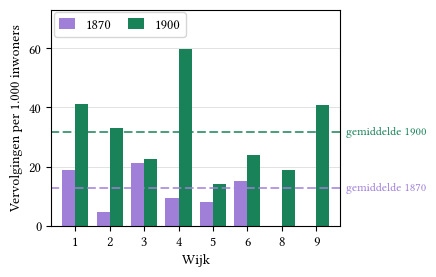

In [6]:
KLEUR_A = KLEUR_LAAT    # 1900
KLEUR_B = KLEUR_VROEG   # 1870

x = np.arange(len(df))
breedte = 0.38

fig, ax = plt.subplots(figsize=figsize(1.0, 0.62))

ax.bar(x - breedte / 2, df["a"], breedte, label=LABEL_A, color=KLEUR_B, linewidth=0)
ax.bar(x + breedte / 2, df["b"], breedte, label=LABEL_B, color=KLEUR_A, linewidth=0)

for gem, kleur, label in ((gem_a, KLEUR_B, LABEL_A), (gem_b, KLEUR_A, LABEL_B)):
    ax.axhline(gem, color=kleur, linestyle=(0, (5, 3)), linewidth=1.1, dash_capstyle="round", zorder=1.5)
    ax.annotate(
        f"gemiddelde {label}",
        xy=(1.0, gem), xycoords=("axes fraction", "data"),
        xytext=(4, 0), textcoords="offset points",
        va="center", ha="left", fontsize=CORPS_KLEIN, color=kleur, annotation_clip=False,
    )

ax.set_xticks(x, df["wijk"])
ax.yaxis.grid(True)
ax.set_xlabel("Wijk")
ax.set_ylabel("Vervolgingen per 1.000 inwoners")
ax.set_xlim(-0.7, len(df) - 0.3)
ax.margins(y=0.08)
ax.set_ylim(0, df[["a", "b"]].max().max() * 1.22)  # ruimte voor de legende

ax.legend(loc="upper left", ncol=2, handlelength=1.1, handleheight=0.9,
          columnspacing=1.2, borderaxespad=0.2)

# vaste marges (geen bbox 'tight'), zodat de figuur met de labels rechts precies 108 mm breed blijft
fig.subplots_adjust(left=0.11, right=0.79, bottom=0.15, top=0.97)
plt.show()

In [7]:
pas_breedte_aan(fig)
fig.savefig(FIGUREN / "2.3_vervolgingen_per_wijk.png", dpi=300, bbox_inches=None)